<h2>读入数据集并分析</h2>

In [1]:
import numpy as np
import pandas as pd

data2=pd.read_csv(r"ionosphere.data",',',encoding='utf-8')   #读取数据集
#显示数据集的前五条
print(data2.head())
print('删除前的数据集大小为:{}'.format(data2.shape))
data2.drop_duplicates(inplace=True)  #删除重复数据
# data.replace('?', pd.NA, inplace=True)
# data.dropna(inplace=True)   #删除缺失值
print('删除后的数据集大小为:{}'.format(data2.shape))
header=range(35)
data2.columns=header
data2=data2.drop(columns=[1])  #删除第二列
header=range(34)
data2.columns=header
# data2.to_excel('wdbc.xlsx', sheet_name='data') #写到excel里方便分析一下

   1  0  0.99539  -0.05889  0.85243  0.02306  0.83398  -0.37708      1.1  \
0  1  0  1.00000  -0.18829  0.93035 -0.36156 -0.10868  -0.93597  1.00000   
1  1  0  1.00000  -0.03365  1.00000  0.00485  1.00000  -0.12062  0.88965   
2  1  0  1.00000  -0.45161  1.00000  1.00000  0.71216  -1.00000  0.00000   
3  1  0  1.00000  -0.02401  0.94140  0.06531  0.92106  -0.23255  0.77152   
4  1  0  0.02337  -0.00592 -0.09924 -0.11949 -0.00763  -0.11824  0.14706   

   0.03760  ...  -0.51171  0.41078  -0.46168  0.21266  -0.34090  0.42267  \
0 -0.04549  ...  -0.26569 -0.20468  -0.18401 -0.19040  -0.11593 -0.16626   
1  0.01198  ...  -0.40220  0.58984  -0.22145  0.43100  -0.17365  0.60436   
2  0.00000  ...   0.90695  0.51613   1.00000  1.00000  -0.20099  0.25682   
3 -0.16399  ...  -0.65158  0.13290  -0.53206  0.02431  -0.62197 -0.05707   
4  0.06637  ...  -0.01535 -0.03240   0.09223 -0.07859   0.00732  0.00000   

   -0.54487  0.18641  -0.45300  g  
0  -0.06288 -0.13738  -0.02447  b  
1  -0.24180  0

D:\anacondainstall\lib\site-packages\IPython\core\interactiveshell.py:3331: FutureWarning: In a future version of pandas all arguments of read_csv except for the argument 'filepath_or_buffer' will be keyword-only
  exec(code_obj, self.user_global_ns, self.user_ns)


In [2]:
data2.replace({'b': 1, 'g': 0}, inplace=True)
data2[33].value_counts()

0    224
1    125
Name: 33, dtype: int64

<h2>评估指标相关函数</h2>

<h3>一、定义绘制混淆矩阵的函数</h3>

In [3]:
from sklearn import metrics
from sklearn.metrics import classification_report
import itertools
import matplotlib.pyplot as plt
import numpy as np
# 绘制混淆矩阵
def plot_confusion_matrix(cm, classes, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)
    plt.ylim(len(classes) - 0.5, -0.5)
    fmt =  'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

<h3>二、定义绘制ROC曲线的函数</h3>

In [4]:
from sklearn.metrics import roc_curve, auc
def plot_roc_curve(y,score):
    fpr, tpr, thresholds = roc_curve(y, score)

    # 计算AUC
    roc_auc = auc(fpr, tpr)

    # 绘制ROC曲线
    plt.title('Receiver Operating Characteristic')
    plt.plot(fpr, tpr, 'b', label = 'AUC = %0.4f' % roc_auc)
    plt.legend(loc = 'lower right')
    plt.plot([0, 1], [0, 1],'r--')
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.ylabel('True Positive Rate')
    plt.xlabel('False Positive Rate')
    plt.show()

<h2>事前准备：创建训练集和测试集</h2>

In [6]:
n=0.8
data2 = data2.apply(pd.to_numeric)
classnumber=data2.value_counts()

bad=data2[data2[33]==1]
good=data2[data2[33]==0]

bad=bad.sample(len(bad),random_state=0)
good=good.sample(len(good),random_state=0)

#分层抽样后相连,创建训练集和测试集
train_X=pd.concat([bad.iloc[:int(len(bad)*0.8),:-1],good.iloc[:int(len(good)*0.8),:-1]],axis=0)
train_y=pd.concat([bad.iloc[:int(len(bad)*0.8),-1],good.iloc[:int(len(good)*0.8),-1]],axis=0)
test_X=pd.concat([bad.iloc[int(len(bad)*0.8):,:-1],good.iloc[int(len(good)*0.8):,:-1]],axis=0)
test_y=pd.concat([bad.iloc[int(len(bad)*0.8):,-1],good.iloc[int(len(good)*0.8):,-1]],axis=0)

#做归一化处理后再进行knn训练
# mins = np.min(train_X, axis=0)
# maxs = np.max(train_X, axis=0)
# train_X = (train_X - mins) / (maxs - mins)
#
# mins = np.min(test_X, axis=0)
# maxs = np.max(test_X, axis=0)
# test_X = (test_X - mins) / (maxs - mins)

In [7]:
X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

In [21]:
accuracy=[] #存放每个特征的准确率
k=7

for i in range(X_train.shape[1]):
    result=[]   #存放预测结果
    for x in X_test:
        dis=(x-X_train) ** 2
        dis=dis.transpose()
        subdis=dis[i]
        index=subdis.argsort()     #返回数组排序后数组元素的索引
        index=index[:k]
        count=np.bincount(y_train[index])      #返回数组中元素出现的次数，必须是自然数
        result.append(count.argmax())     #返回出现最多元素的索引
    num_correct = np.sum(result == y_test)
    accuracy .append( num_correct / len(y_test))

index = [i for i, x in enumerate(accuracy) if x > 0.8]
print(accuracy)
print(index)

[0.7428571428571429, 0.7857142857142857, 0.8142857142857143, 0.7571428571428571, 0.8142857142857143, 0.7142857142857143, 0.7857142857142857, 0.7714285714285715, 0.8, 0.7714285714285715, 0.7857142857142857, 0.7, 0.8142857142857143, 0.7571428571428571, 0.7857142857142857, 0.8, 0.8285714285714286, 0.7142857142857143, 0.7714285714285715, 0.7714285714285715, 0.8, 0.7142857142857143, 0.7857142857142857, 0.7571428571428571, 0.8285714285714286, 0.7857142857142857, 0.7571428571428571, 0.8428571428571429, 0.8285714285714286, 0.8, 0.8285714285714286, 0.7857142857142857, 0.8428571428571429]
[2, 4, 12, 16, 24, 27, 28, 30, 32]


In [35]:
subXtrain=X_train[:,index]
subXtest=X_test[:,index]

<h1>一、KNN算法的实现</h1>可以多分类，数值特征即可

<h3>knn类的编写</h3>

In [8]:
class KNN:
    #初始化方法，k为选择的邻居个数
    def __init__(self,k):
        self.k=k

    def fit(self,X,y):
        """
        训练方法，在KNN算法中仅仅是转换数据类型格式，使得传进来的X和y可以是多种数据类型
        :parameters
        -----
        X:训练样本，形状为[样本数，特征数]
        y:训练样本的实际值，形状为[样本数]
        """
        self.X=np.asarray(X)
        self.y=np.asarray(y)

    def predict(self,X):
        """
        预测方法
        :param X:预测样本，形状为[样本数，特征数]
        -----
        :return:
        -----
         result:预测结果，是测试集预测结果的合集
        """
        X=np.asarray(X)
        result=[]
        score=[]
        for x in X:
            dis=np.sum((x-self.X) ** 2,axis=1)     #计算距离，此时每行元素即为测试样本到训练样本的距离的平方
            index=dis.argsort()     #返回数组排序后数组元素的索引
            index=index[:self.k]
            count=np.bincount(self.y[index])      #返回数组中元素出现的次数，必须是自然数
            result.append(count.argmax())     #返回出现最多元素的索引
            score.append(count[0]/self.k)

        return np.asarray(result),score

<h3>knn类的训练</h3>

In [29]:
knn=KNN(k=9)
knn.fit(subXtrain,train_y)
result,score=knn.predict(subXtest)

<h3>输出评价指标</h3>

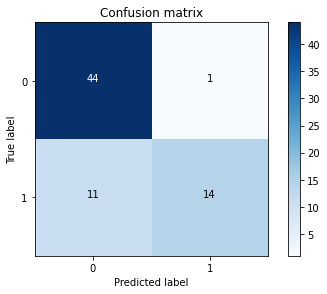

              precision    recall  f1-score   support

           0       0.80      0.98      0.88        45
           1       0.93      0.56      0.70        25

    accuracy                           0.83        70
   macro avg       0.87      0.77      0.79        70
weighted avg       0.85      0.83      0.82        70



In [30]:
from sklearn import metrics
from sklearn.metrics import classification_report

matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

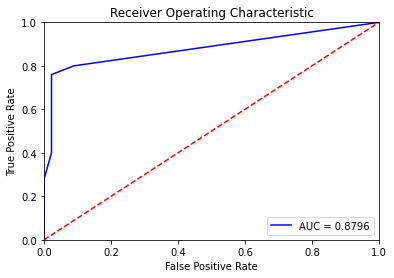

In [85]:
y_test=np.asarray(test_y)
score=[1-x for x in score]
plot_roc_curve(y_test,score)

<font color="red">可以看到准确率很高，说明10个特征基本都是有用的，且权值大致相等，分布集中，所以分类效果较好

<h1>二、朴素贝叶斯决策算法的实现</h1>多分类应该也可以，该贝叶斯是多项式贝叶斯，输入需为离散量，要解决连续问题或许另写高斯贝叶斯

<h3>朴素贝叶斯类的编写</h3>

In [9]:
class NaiveBayes:

    def __init__(self):

        self.lablepl={}  #用来存放类条件概率的字典{类别名：出现概率}
        self.features=[]    #计算每个特征出现的概率

    def fit(self,X_train,y_train):
        self.X_train=np.asarray(X_train)
        self.y_train=np.asarray(y_train)

        #1、计算类条件概率
        # 统计元素出现的次数
        self.labels, self.counts = np.unique(self.y_train, return_counts=True)
        # 将元素名和元素个数转换为字典格式
        count_dict = dict(zip(self.labels, self.counts))
        for k,v in count_dict.items():
            self.lablepl[k]=v/len(self.y_train)

        #2、计算每个特征出现的概率
        numberf=len(self.X_train[0])
        for label in self.labels:
            feature=[]
            for j in range(numberf):    #按照特征数往feature里加入空字典
                feature.append({})
            for i in range(len(self.y_train)):   #取出一条数据
                if self.y_train[i]==label:
                    for k in range(len(self.X_train[0])):
                        if self.X_train[i][k] not in feature[k]:
                            feature[k][self.X_train[i][k]]=1
                        else:
                            feature[k][self.X_train[i][k]]=feature[k][self.X_train[i][k]]+1
            self.features.append(feature)

        for i in range(len(self.labels)):
            for j in range(len(self.X_train[0])):
                for key in self.features[i][j]:
                    self.features[i][j][key]=self.features[i][j][key]/self.counts[i]

    def predict(self,X_test):
        self.X_test=np.asarray(X_test)
        result=[]
        possiblity=[]
        # for i in range(len(y_test)):    #取出一条测试样本
        for x in self.X_test:
            possible=[]
            for j in range(len(self.labels)):    #分别计算两种标签的概率
                sum=0
                for k in range(len(self.X_test[0])):
                    if x[k] in self.features[j][k]:  #如果测试集的值有在训练集出现过就取出对应概率
                        sum=sum+np.log(self.lablepl[self.labels[j]])  #labels的下标对应的值是labelpl的key
                    else:   #否则按平滑处理
                        sum=sum+np.log(1.0/self.counts[j])
                sum=sum+np.log(self.lablepl[self.labels[j]])
                possible.append(sum)
            possiblity.append(possible)
            index=np.argmax(possible)
            result.append(self.labels[index])
        return result,possiblity

<h3>训练贝叶斯分类器</h3>

In [96]:
nbclasser=NaiveBayes()
nbclasser.fit(train_X,train_y)
result,possiblity=nbclasser.predict(test_X)

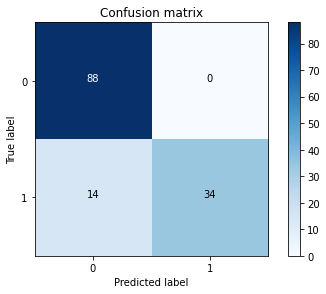

              precision    recall  f1-score   support

           0       0.86      1.00      0.93        88
           1       1.00      0.71      0.83        48

    accuracy                           0.90       136
   macro avg       0.93      0.85      0.88       136
weighted avg       0.91      0.90      0.89       136



In [97]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

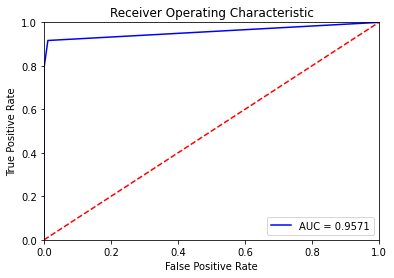

In [98]:
score=[]
for i in range(len(y_test)):
    score.append(possiblity[i][0]/(possiblity[i][0]+possiblity[i][1]))
plot_roc_curve(y_test,score)

可以看到准确率并不高，2能够百分百准确，但4不行，考虑应该是因为该朴素贝叶斯是离散式的朴素贝叶斯，有些特征值在训练集出现了，但在测试集并未出现，所以此时类概率就成了判定因素，但2类又远远高于4类，导致产生了这种情况。

<h1>二（改）、以高斯分布估计概率的朴素贝叶斯实现<h1>

In [28]:
# def normal_distribution(x,mean,variance):
#     a1=math.exp(-((x - mean) ** 2) / (2 * variance))
#     a2=math.sqrt(2 * variance * math.pi)
#     print(a2)
#     return 1/a1*a2

In [11]:
import math
def normal_distribution(x,mean,variance):
    a1=math.exp(-((x - mean) ** 2) / (2 * variance))
    a2=math.sqrt(2 * variance * math.pi)
    if a2==0:
        return 0.5
    else:
        return (1/a2)*a1

class GNaiveBayes:

    def __init__(self):

        self.lablepl={}  #用来存放类条件概率的字典{类别名：出现概率}
        self.dic={}  #键为标签，值为一个存有均值和方差的列表


    def fit(self,X_train,y_train):
        self.X_train=np.asarray(X_train)
        self.y_train=np.asarray(y_train)

        #1、计算类条件概率
        # 统计元素出现的次数
        self.labels, self.counts = np.unique(self.y_train, return_counts=True)
        # 将元素名和元素个数转换为字典格式
        count_dict = dict(zip(self.labels, self.counts))
        for k,v in count_dict.items():
            self.lablepl[k]=v/len(self.y_train)

        #2、每列特征出现的均值和方差
        numberf=len(self.X_train[0])
        for label in self.labels:
            subx=X_train[y_train==label]
            he=[]   #第一个元素为均值，第二个元素为方差
            means=np.mean(subx,axis=0)
            he.append(means)
            variance = np.var(subx, axis=0,ddof=1)
            he.append(variance)
            self.dic[label]=he


    def predict(self,X_test):
        self.X_test=np.asarray(X_test)
        result=[]
        score=[]
        for x in self.X_test:   #取出一条测试样本
            possible=[]
            # print(x)
            for key,value in self.dic.items():
                sum=0
                for i in range(len(x)):
                    sum+=np.log(normal_distribution(x[i],value[0][i],value[1][i]))
                sum=sum+np.log(self.lablepl[key])
                possible.append(sum)
            index=np.argmax(possible)
            result.append(index)
            score.append(possible[0]/(possible[0]+possible[1]))

        #     for j in range(len(self.labels)):    #分别计算两种标签的概率
        #         sum=0
        #         for k in range(len(self.X_test[0])):
        #             if x[k] in self.features[j][k]:  #如果测试集的值有在训练集出现过就取出对应概率
        #                 sum=sum+np.log(self.lablepl[self.labels[j]])  #labels的下标对应的值是labelpl的key
        #             else:   #否则按平滑处理
        #                 sum=sum+np.log(1.0/self.counts[j])
        #         sum=sum+np.log(self.lablepl[self.labels[j]])
        #         possible.append(sum)
        #     possiblity.append(possible)
        #     index=np.argmax(possible)
        #     result.append(self.labels[index])
        return result,score

# nbclasser=GNaiveBayes()
# nbclasser.fit(subXtrain,train_y)
# result,score=nbclasser.predict(subXtest)

In [87]:
print(result)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0]


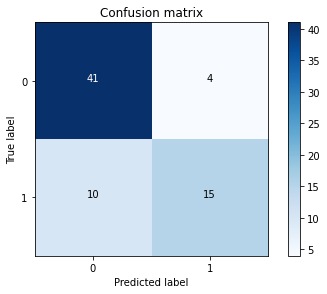

              precision    recall  f1-score   support

           0       0.80      0.91      0.85        45
           1       0.79      0.60      0.68        25

    accuracy                           0.80        70
   macro avg       0.80      0.76      0.77        70
weighted avg       0.80      0.80      0.79        70



In [37]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

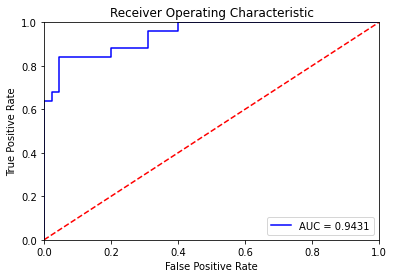

In [89]:
plot_roc_curve(y_test,score)

<h1>五、逻辑回归的实现</h1>

In [38]:
X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

# #重新赋值，把恶性赋值为1，把良性赋值为0
# y_train=np.where(y_train==4,1,y_train)
# y_train=np.where(y_train==2,0,y_train)
# y_test=np.where(y_test==4,1,y_test)
# y_test=np.where(y_test==2,0,y_test)
# print(y_test)

#X都各加一列作为偏置
subXtrain = np.c_[np.ones(subXtrain.shape[0]),subXtrain]
subXtest = np.c_[np.ones(subXtest.shape[0]),subXtest]
print(subXtest.shape)

(70, 10)


In [23]:
#1、定义sigmoid函数
def sigmoid(x):
    return  1 / (1 + np.exp(-x))

In [24]:
#定义训练函数
learning_rate=0.1  #设置学习率
num_iterations=1000   #设置迭代次数
threshold=0.0003     #设置阈值，当梯度小于阈值的时候就会停止训练

def lrfit(X, y, learning_rate=0.1, num_iterations=1000, threshold=0.0003):

        #初始化权重
        theta = np.ones(X.shape[1])

        #初始化梯度值
        gradient=np.zeros(X.shape[1])

        #开始梯度下降训练
        for n in range(num_iterations):
            for j in range(X.shape[1]): #遍历每个特征
                jf=0

                for i in range(X.shape[0]): #遍历每个样本
                    z=np.dot(X[i],theta)
                    h=sigmoid(z)
                    jf+=(h-y[i])*X[i][j]

                jf/=X.shape[0]
                gradient[j]=jf

            theta=theta-learning_rate*gradient
            if abs(gradient.sum()) <threshold:
                return theta

        return theta

In [39]:
theta=lrfit(X_train,y_train)
print(theta)

[ 2.03951002 -0.95639073 -1.54477974 -0.5750365  -1.62792905 -0.29055404
 -0.67859617 -0.97480533 -0.1766442  -0.30496889  0.51678112  0.15968339
  0.34662167 -0.48047734 -0.63802183  0.14903406 -0.05005233 -0.22894635
  0.18896532 -0.46122366 -0.05123527  1.41554095 -0.59861118 -0.12175735
 -0.22636026 -0.80387273  1.80836933 -0.01384698 -0.54745825 -0.33610065
 -0.55898801  0.3852167   0.29142936  0.73071822]


In [26]:
def lrpredict(X_test,theta):
    result=[]
    score=[]
    for x in X_test:
        z=sigmoid(np.dot(x,theta))
        if z>0.5:
            result.append(1)
        else:
            result.append(0)
        score.append(z)
    return result,score

In [41]:
result,score=lrpredict(X_test,theta)

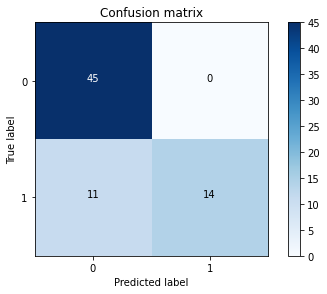

              precision    recall  f1-score   support

           0       0.80      1.00      0.89        45
           1       1.00      0.56      0.72        25

    accuracy                           0.84        70
   macro avg       0.90      0.78      0.80        70
weighted avg       0.87      0.84      0.83        70



In [42]:
matrix=metrics.confusion_matrix(y_test, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(y_test, result))

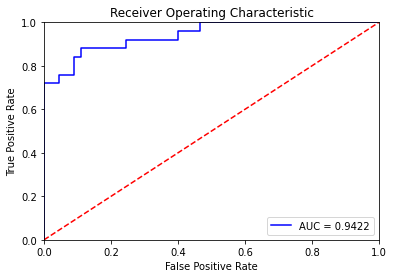

In [43]:
plot_roc_curve(y_test,score)

In [40]:
theta=lrfit(subXtrain,y_train,num_iterations=6000)
print(theta)

[ 0.08908453 -1.15759979 -1.12443437 -1.15884453 -0.36188903 -0.58991685
 -1.52316225  0.14148258  0.53882975  0.70110805]


In [42]:
result,score=lrpredict(subXtest,theta)

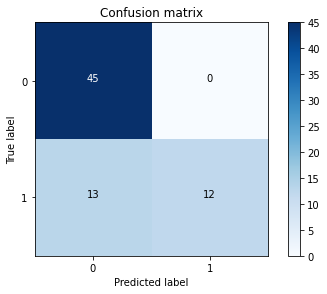

              precision    recall  f1-score   support

           0       0.78      1.00      0.87        45
           1       1.00      0.48      0.65        25

    accuracy                           0.81        70
   macro avg       0.89      0.74      0.76        70
weighted avg       0.86      0.81      0.79        70



In [43]:
matrix=metrics.confusion_matrix(y_test, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(y_test, result))

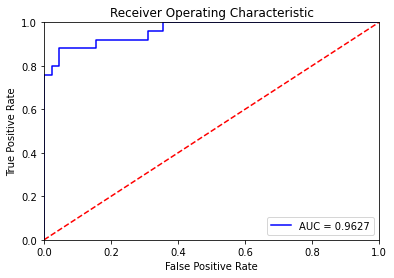

In [47]:
plot_roc_curve(y_test,score)

<h1>特征选择</h1>

In [12]:
featureX=data2.drop(columns=[0])
featurey=data2[0]
featureX=np.asarray(featureX)
featurey=np.asarray(featurey)

mins = np.min(featureX, axis=0)
maxs = np.max(featureX, axis=0)
featureX_scaled = (featureX - mins) / (maxs - mins)

In [13]:
def relief(X, y):
    n_samples = X.shape[0]
    n_features =X.shape[1]
    weights = np.zeros(n_features)

    for i in range(n_samples):
        # 找到样本最近的两类邻居
        dis=np.sum((X[i]-X) ** 2,axis=1)     #计算距离，此时每行元素即为测试样本到训练样本的距离的平方
        nearest_neighbor=dis.argsort()     #返回数组排序后数组元素的索引
        same=0
        diffrent=0
        for k in range(len(nearest_neighbor)):
            if y[i]==y[nearest_neighbor[k]] and same<=1:
                if same==0: #排除自己与自己距离最近的情况
                    same=1
                    continue
                for j in range(n_features):
                    weights[j] -= abs(X[i, j] - X[nearest_neighbor[k], j])
                same=2
            elif y[i]!=y[nearest_neighbor[k]] and diffrent ==0:
                 for j in range(n_features):
                    weights[j] += abs(X[i, j] - X[nearest_neighbor[k], j])
                    diffrent=1
            if same==2 and diffrent==1:
                break
        # 更新i的特征的权重
        # for j in range(n_features):
        #     if y[i] == y[nearest_neighbor]:
        #         weights[j] += (X[i, j] - X[nearest_neighbor, j])**2
        #     else:
        #         weights[j] -= (X[i, j] - X[nearest_neighbor, j])**2

    top_k = np.argsort(weights)
    # top_k = weights

    return top_k

top=relief(featureX_scaled,featurey)

In [14]:
print(top)

[25  1  3 31 13 29 21 19  5 27 15  9 23 17 11  7 26 30 28 20 22 18 24  6
 14 10  8 16 12  4  2  0 32]


In [29]:
top15=top[-15:]
print(top15)
subXtrain=X_train[:,top15]
subXtest=X_test[:,top15]

[28 20 22 18 24  6 14 10  8 16 12  4  2  0 32]


In [30]:
knn=KNN(k=9)
knn.fit(subXtrain,train_y)
result,score=knn.predict(subXtest)

In [31]:
print(result)

[0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


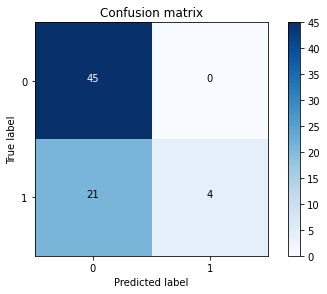

              precision    recall  f1-score   support

           0       0.68      1.00      0.81        45
           1       1.00      0.16      0.28        25

    accuracy                           0.70        70
   macro avg       0.84      0.58      0.54        70
weighted avg       0.80      0.70      0.62        70



In [32]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

In [33]:
nbclasser=GNaiveBayes()
nbclasser.fit(subXtrain,y_train)
result,score=nbclasser.predict(subXtest)

D:\anacondainstall\lib\site-packages\ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in double_scalars
  This is separate from the ipykernel package so we can avoid doing imports until
D:\anacondainstall\lib\site-packages\ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in double_scalars
  This is separate from the ipykernel package so we can avoid doing imports until


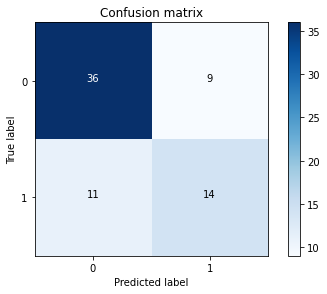

              precision    recall  f1-score   support

           0       0.77      0.80      0.78        45
           1       0.61      0.56      0.58        25

    accuracy                           0.71        70
   macro avg       0.69      0.68      0.68        70
weighted avg       0.71      0.71      0.71        70



In [34]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

In [35]:
subXtrain = np.c_[np.ones(X_train.shape[0]),subXtrain]
subXtest = np.c_[np.ones(X_test.shape[0]),subXtest]

In [39]:
theta=lrfit(subXtrain,y_train,num_iterations=6000)
print(theta)

[ 3.9121473  -0.36203506  0.0062257   0.03973211 -0.27961797 -0.24055445
 -1.0534476   0.13054174 -0.07451278 -0.57076239 -0.33636055  0.02285902
 -0.55915355 -0.97099238 -4.78611703  1.72018497]


In [40]:
result,score=lrpredict(subXtest,theta)

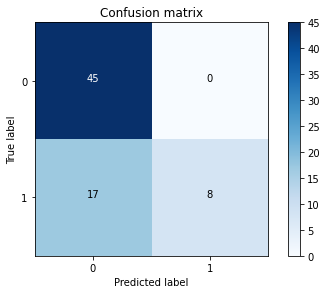

              precision    recall  f1-score   support

           0       0.73      1.00      0.84        45
           1       1.00      0.32      0.48        25

    accuracy                           0.76        70
   macro avg       0.86      0.66      0.66        70
weighted avg       0.82      0.76      0.71        70



In [41]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))